# 1. Data exploration

Paris PM2.5 daily means (OpenAQ). Owner: Prem — Phase 1.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root))
import os
os.chdir(project_root)

from src.eda import adf_table, count_missing, impute_linear, rolling_mean_std, suggest_sarima_orders
from src.load_data import load_daily_series
from src.plots import plot_acf_pacf, plot_rolling, plot_series, save_current_figure, save_figure

DATA_PATH = project_root / "data/processed/pm25_paris_daily.csv"
(project_root / "reports/figures").mkdir(parents=True, exist_ok=True)

raw = load_daily_series(DATA_PATH)
raw.head()

date
2023-01-01    10.004167
2023-01-02     6.608333
2023-01-03     7.954167
2023-01-04     4.141667
2023-01-05     4.937500
Freq: D, Name: pm25, dtype: float64

## Full series, zoomed month, and rolling mean/std

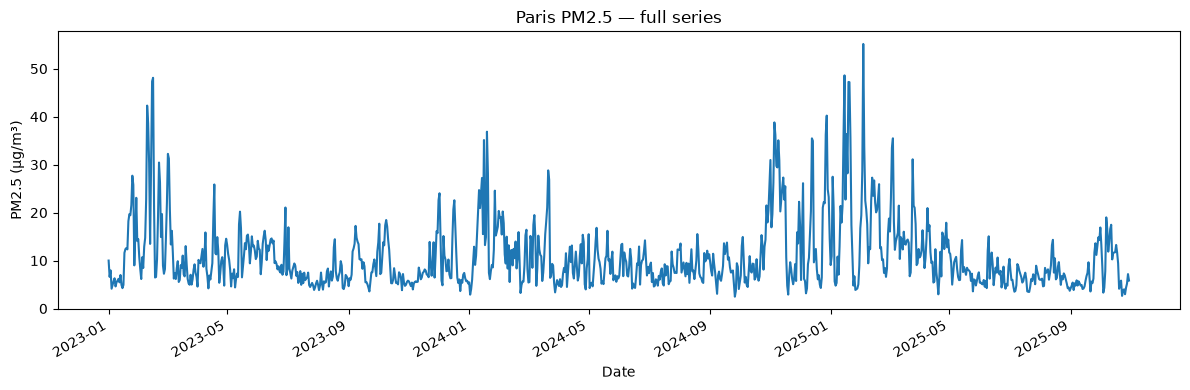

In [2]:
ax = plot_series(raw.dropna(), title="Paris PM2.5 — full series")
save_figure(ax, "01_full_series.png")
plt.show()

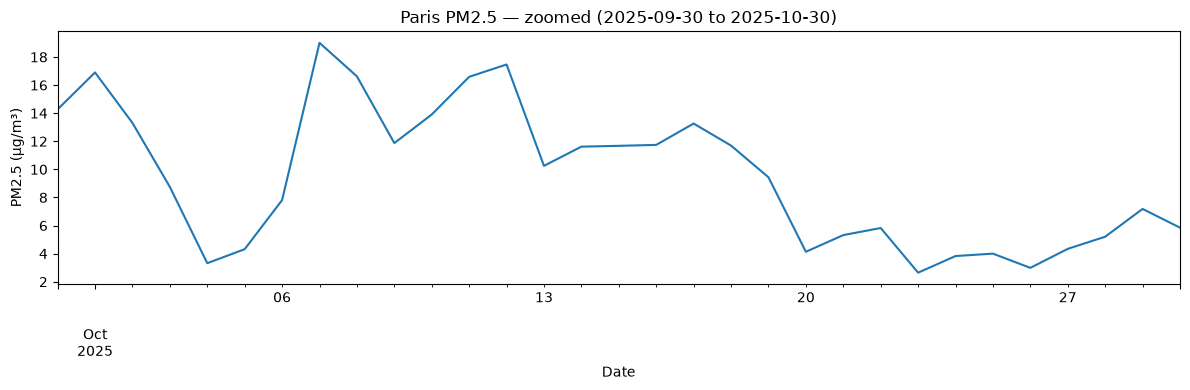

In [3]:
clean = raw.dropna()
zoom_days = min(30, max(7, len(clean) - 1))
zoom_end = clean.index.max()
zoom_start = zoom_end - pd.Timedelta(days=zoom_days)
zoom = raw.loc[zoom_start:zoom_end].dropna()
ax = plot_series(zoom, title=f"Paris PM2.5 — zoomed ({zoom_start.date()} to {zoom_end.date()})")
save_figure(ax, "01_zoomed_month.png")
plt.show()

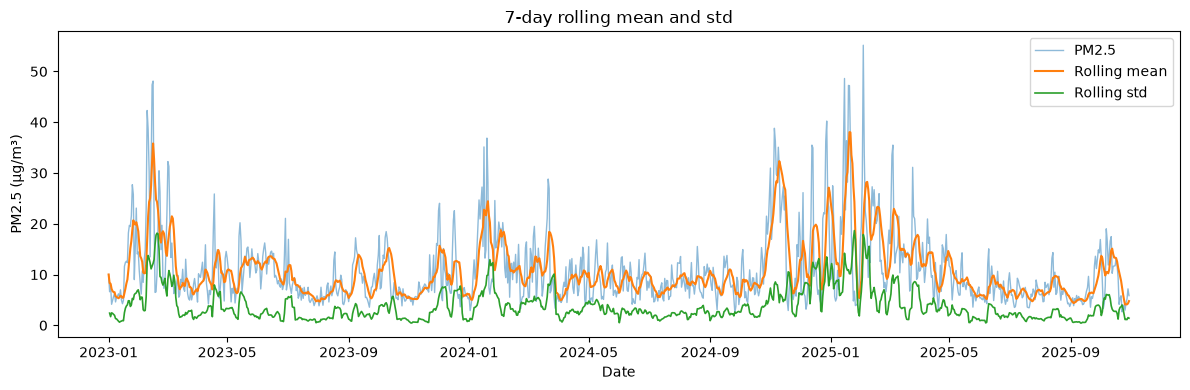

In [4]:
roll_mean, roll_std = rolling_mean_std(raw.dropna(), window=7)
ax = plot_rolling(raw.dropna(), roll_mean, roll_std, title="7-day rolling mean and std")
save_figure(ax, "01_rolling_mean_std.png")
plt.show()

### What the plots show

- **Level and skew:** mean 10.8 µg/m³, median 8.6, maximum 55.2 (2025-02-03). The distribution is right-skewed (skewness 2.2): 102 days exceed 20 µg/m³ and 31 days exceed 30, all of them short winter episodes.
- **Strong annual cycle:** winter (Dec-Feb) averages 15.0 µg/m³ and summer (Jun-Aug) 7.9. Spring and autumn lie in between (10.8 and 9.9).
- **Variance depends on the season:** the standard deviation is 10.2 in winter against 3.0 in summer, and the median 7-day rolling std is about 6.2 in winter against 2.0 in summer. The series is therefore heteroscedastic, with larger swings when the level is high.
- **No obvious long-term trend:** yearly means are 10.2 (2023), 11.2 (2024) and 11.0 (2025, Jan-Oct only), so differences are small compared with the seasonal amplitude.

## Missing timestamps and imputation

The daily calendar has 1034 days (2023-01-01 to 2025-10-30), of which 20 are missing (about 1.9%). All gaps are isolated single days (longest gap: 1 day).

**Choice:** linear interpolation on the daily calendar (`impute_linear`), with edge `ffill`/`bfill` only if the first/last days are missing.

**Why not forward-fill:** ffill creates flat segments that artificially inflate ACF at lag 1. With only one-day gaps, interpolating between the two neighbouring days introduces very little distortion.

In [5]:
missing = count_missing(raw)
print(
    f"expected_days={missing.expected_days}\n"
    f"observed_days={missing.observed_days}\n"
    f"missing_timestamps={missing.missing_timestamps}\n"
    f"missing_values_in_file={missing.missing_values}"
)
if len(missing.missing_dates):
    print("first missing dates:", list(missing.missing_dates[:10]))

series = impute_linear(raw)
assert series.isna().sum() == 0
series.describe()

expected_days=1034
observed_days=1014
missing_timestamps=20
missing_values_in_file=20
first missing dates: [Timestamp('2023-01-10 00:00:00'), Timestamp('2023-04-05 00:00:00'), Timestamp('2023-06-13 00:00:00'), Timestamp('2023-07-25 00:00:00'), Timestamp('2023-09-28 00:00:00'), Timestamp('2023-10-13 00:00:00'), Timestamp('2023-11-02 00:00:00'), Timestamp('2023-12-03 00:00:00'), Timestamp('2023-12-18 00:00:00'), Timestamp('2024-01-13 00:00:00')]


count    1034.000000
mean       10.794294
std         7.095248
min         2.479167
25%         6.081771
50%         8.618750
75%        13.177083
max        55.162500
Name: pm25, dtype: float64

## ADF stationarity tests

In [6]:
adf = adf_table(series)
display(adf)
raw_stationary = bool(adf.loc[adf["series"] == "raw", "stationary_5pct"].iloc[0])
print(
    "Raw series is",
    "stationary at 5%. Use d=0" if raw_stationary else "NOT stationary at 5%. Prefer d=1",
    "for SARIMA.",
)

/home/soums/Documents/MesCours/MSc_AIS/AIS_S3/Time_Series_Analysis/tsa_project/src/eda.py:56: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue, used_lag, nobs, *_ = adfuller(clean, autolag="AIC")
/home/soums/Documents/MesCours/MSc_AIS/AIS_S3/Time_Series_Analysis/tsa_project/src/eda.py:56: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue, used_lag, nobs

,series,adf_stat,pvalue,used_lag,nobs,stationary_5pct
0,raw,-4.419287,2.743525e-04,14,1019,True
1,diff_1,-11.654238,2.003213e-21,18,1014,True


Raw series is stationary at 5%. Use d=0 for SARIMA.


### ADF interpretation

The raw series is stationary at the 5% level (ADF statistic -4.42, p = 2.7e-4, 14 lags), so `d = 0` is the starting point for ARIMA/SARIMA. The first difference is also stationary (p ≈ 2e-21), but it is not needed.

ADF only rejects a unit root. It does not mean the series has no seasonality: the annual cycle above is real, but it is a recurring pattern around a stable mean, not a stochastic trend.

## ACF/PACF and suggested orders

Inspect lag-1 behaviour for `(p, q)` and lags 7 / 14 for weekly seasonal `(P, Q, s=7)`.

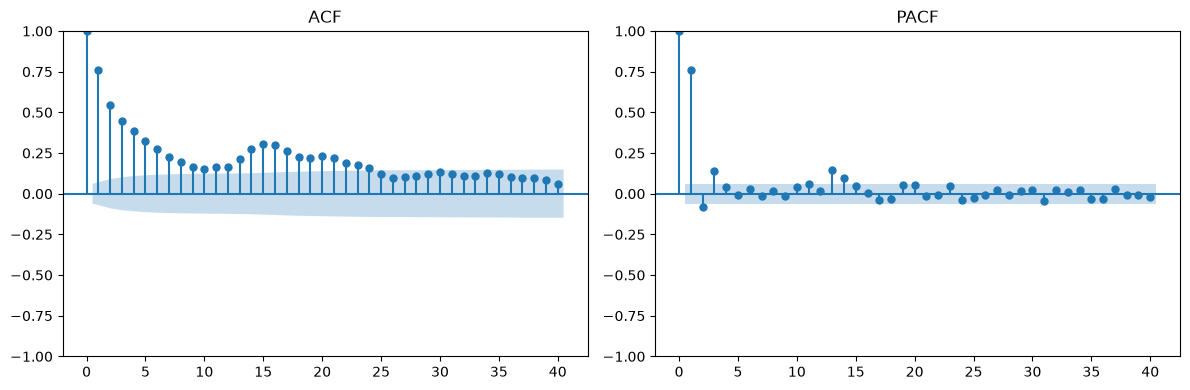

Starter order: (1, 0, 1)
Starter seasonal_order: (1, 0, 1, 7)
Starting points only: final orders are selected by AIC/BIC on the training set in 03_forecasting.ipynb.


In [7]:
plot_acf_pacf(series, lags=40)
save_current_figure("01_acf_pacf.png")
plt.show()

prefer_diff = not raw_stationary
orders = suggest_sarima_orders(seasonal_period=7, prefer_diff=prefer_diff)
print("Starter order:", orders["order"])
print("Starter seasonal_order:", orders["seasonal_order"])
print("Starting points only: final orders are selected by AIC/BIC on the training set in 03_forecasting.ipynb.")

### ACF/PACF interpretation

- **PACF:** a large spike at lag 1 (about 0.76), then mostly inside the confidence band, apart from small values at lag 3 and around lag 13. This points to a low-order autoregressive process (AR(1) to AR(3)).
- **ACF:** slow decay from 0.76 at lag 1, with a hump around lags 14-17 (about 0.3), staying above the confidence band up to lag 35. This persistence comes from multi-day pollution episodes and from the annual cycle.
- **Weekly seasonality is weak:** there are no sharp spikes at lags 7, 14 or 21. The ACF at lag 7 is about 0.23, which is just the continuation of the smooth decay. Day-of-week means differ by only about 1.8 µg/m³ (Sunday 9.7 vs Wednesday 11.4).
- **Consequence:** `suggest_sarima_orders` is only a starting point. With weak weekly seasonality, seasonal differencing (`D = 1`) over-differences the series, so `D = 0` is the default now. Final orders come from the AIC/BIC search in `03_forecasting.ipynb`.